In [1]:
#!pip install grape
from grape import Graph

/home/sanya/.conda/envs/kg-embed/lib/python3.8/site-packages/requests/__init__.py:109: RequestsDependencyWarning: urllib3 (1.26.9) or chardet (5.1.0)/charset_normalizer (2.0.12) doesn't match a supported version!
  warnings.warn(
/home/sanya/.conda/envs/kg-embed/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import numpy as np
import pandas as pd
import pickle

In [3]:
import matplotlib.pyplot as plt

## Notebook to create edge prediction pipeline with NP-KG (v2.1) and evaluate embeddings

In [4]:
KG_PATH = '../../np-kg/resources/knowledge_graphs/'
EMBED_PATH = 'embeddings/'
DATA_PATH = '../data/'
DIR_PATH = 'results/'

In [5]:
npkg = Graph.from_csv(
    node_path=KG_PATH+'nodeTypes_CURIE_v3.0.0.tsv',
    node_list_node_types_column_number=1,
    nodes_column_number=0,
    node_list_separator='\t',
    node_list_header=True,
    edge_path=KG_PATH+'NP-KG_BETWEENNESS-WEIGHTED-PK-CURIE-HASHED_v3.0.0.tsv',
    edge_list_separator='\t',
    edge_list_header=True,
    edge_list_edge_types_column_number=1,
    sources_column_number=0,
    destinations_column_number=2,
    weights_column_number=3,
    directed=True,
    verbose=True
)

In [6]:
#(number of components, number of nodes of the smallest component, number of nodes of the biggest component)
npkg.get_number_of_connected_components()

(348, 1, 1089125)

In [7]:
npkg = npkg.remove_disconnected_nodes()

## Load embeddings

In [8]:
from grape import EmbeddingResult

In [22]:
model_name = 'TransE_l1'
with open('embeddings/npkg_'+model_name+'_embeddings.pickle', 'rb') as f:
    transe_embedding_dict = pickle.load(f)
transe_embedding = EmbeddingResult.load(transe_embedding_dict)
transe_embedding.get_node_embedding_from_index(0)

,0,1,2,3,4,5,6,7,8,9,...,390,391,392,393,394,395,396,397,398,399
entity,,,,,,,,,,,,,,,,,,,,,
clo:0035452,-0.017144,0.026280,0.016505,-0.026712,0.011255,-0.016669,0.000365,-0.004368,-0.017974,-0.027560,...,0.024926,0.018848,-0.003885,0.008644,0.009808,0.008074,0.006638,-0.024671,0.012864,-0.009459
clo:0000374,-0.004602,-0.027027,-0.004305,-0.013631,-0.019567,0.011372,0.041273,-0.027809,-0.009674,-0.007480,...,-0.006057,0.018146,-0.021681,0.014010,-0.033831,-0.021717,0.037921,-0.008668,0.017929,0.005895
ensembl:ENST00000256362,-0.022936,-0.014642,-0.033662,-0.035045,0.016510,-0.004701,-0.011429,0.026532,0.026691,-0.001963,...,0.032194,-0.011674,-0.036820,-0.016718,0.007127,-0.001612,-0.004708,0.015629,0.035567,-0.012527
so:0000673,0.018465,-0.033552,-0.018579,-0.010986,-0.004078,0.014320,0.030253,-0.030554,0.026595,-0.029279,...,0.046170,-0.007131,-0.010736,-0.020661,-0.002482,-0.009765,-0.006223,0.013704,0.028415,0.003572
ncbigene:55237,-0.027238,0.004067,-0.036024,-0.001426,0.017603,0.004726,0.038429,0.033189,0.005087,0.004143,...,0.032224,0.013217,-0.023572,-0.011071,0.039881,-0.027857,-0.018274,0.000782,0.039644,0.013521
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
pr:p56678,-0.014111,-0.004581,-0.018009,0.016947,-0.010388,-0.035234,-0.002214,-0.000278,-0.029503,-0.024742,...,0.011216,0.028972,0.035449,0.041572,-0.047711,0.025424,0.017413,0.023862,0.006960,0.026952
pr:p69747,-0.033205,-0.015036,-0.021176,0.024073,-0.025183,0.015103,0.021675,-0.002637,0.008651,-0.006513,...,-0.010722,-0.057686,0.030630,0.016603,0.026792,-0.022466,0.023378,0.002999,0.009855,0.011075
pr:p94298,-0.013353,-0.000970,-0.044898,-0.006525,0.010752,-0.035764,0.018990,0.012127,-0.022799,-0.009578,...,0.014862,-0.018567,0.008209,-0.001844,-0.000713,0.010288,0.028599,-0.038287,0.013122,0.005820


In [ ]:
model_name = 'ComplEx'
embed_file_name = 'npkg_'+model_name+'_embeddings.pickle'
with open(EMBED_PATH+embed_file_name, 'rb') as filep:
    complex_embedding_dict = pickle.load(filep)
complex_embedding = EmbeddingResult.load(complex_embedding_dict)

In [ ]:
model_name = 'DistMult'
embed_file_name = 'npkg_'+model_name+'_embeddings.pickle'
with open(EMBED_PATH+embed_file_name, 'rb') as filep:
    distmult_embedding_dict = pickle.load(filep)
distmult_embedding = EmbeddingResult.load(distmult_embedding_dict)

## Visualization

In [23]:
from grape import GraphVisualizer
import matplotlib.pyplot as plt

Edge embedding methods: hadamard, concatenate

In [24]:
%%time
vis_had = GraphVisualizer(npkg, 
                          verbose=True, 
                          edge_embedding_methods="Hadamard", 
                          #decomposition_kwargs=dict(metric="euclidean"),
                          rotate=False)

CPU times: user 13.4 s, sys: 382 ms, total: 13.8 s
Wall time: 4.54 s


In [26]:
%%time
vis_had.fit_nodes(transe_embedding)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 20000 samples in 0.002s...
[t-SNE] Computed neighbors for 20000 samples in 2.114s...
[t-SNE] Computed conditional probabilities for sample 1000 / 20000
[t-SNE] Computed conditional probabilities for sample 2000 / 20000
[t-SNE] Computed conditional probabilities for sample 3000 / 20000
[t-SNE] Computed conditional probabilities for sample 4000 / 20000
[t-SNE] Computed conditional probabilities for sample 5000 / 20000
[t-SNE] Computed conditional probabilities for sample 6000 / 20000
[t-SNE] Computed conditional probabilities for sample 7000 / 20000
[t-SNE] Computed conditional probabilities for sample 8000 / 20000
[t-SNE] Computed conditional probabilities for sample 9000 / 20000
[t-SNE] Computed conditional probabilities for sample 10000 / 20000
[t-SNE] Computed conditional probabilities for sample 11000 / 20000
[t-SNE] Computed conditional probabilities for sample 12000 / 20000
[t-SNE] Computed conditional probabilities for sam

In [27]:
vis_had.plot_nodes(annotate_nodes=True, show_edges=True)

/home/sanya/.conda/envs/kg-embed/lib/python3.8/site-packages/matplotlib/collections.py:1098: UserWarning: Collection without array used. Make sure to specify the values to be colormapped via the `c` argument.
  warnings.warn("Collection without array used. Make sure to "


KeyboardInterrupt: 

In [ ]:
vis_had.plot_node_types()

In [ ]:
vis_had.plot_node_degrees(
                        annotate_nodes=True,
                        show_edges=True
                    )

In [ ]:
vis_had.fit_edges(transe_embedding)

In [ ]:
vis_had.plot_edges()

In [ ]:
vis_had.plot_edge_types()

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 20000 samples in 0.001s...
[t-SNE] Computed neighbors for 20000 samples in 0.441s...
[t-SNE] Computed conditional probabilities for sample 1000 / 20000
[t-SNE] Computed conditional probabilities for sample 2000 / 20000
[t-SNE] Computed conditional probabilities for sample 3000 / 20000
[t-SNE] Computed conditional probabilities for sample 4000 / 20000
[t-SNE] Computed conditional probabilities for sample 5000 / 20000
[t-SNE] Computed conditional probabilities for sample 6000 / 20000
[t-SNE] Computed conditional probabilities for sample 7000 / 20000
[t-SNE] Computed conditional probabilities for sample 8000 / 20000
[t-SNE] Computed conditional probabilities for sample 9000 / 20000
[t-SNE] Computed conditional probabilities for sample 10000 / 20000
[t-SNE] Computed conditional probabilities for sample 11000 / 20000
[t-SNE] Computed conditional probabilities for sample 12000 / 20000
[t-SNE] Computed conditional probabilities for sam

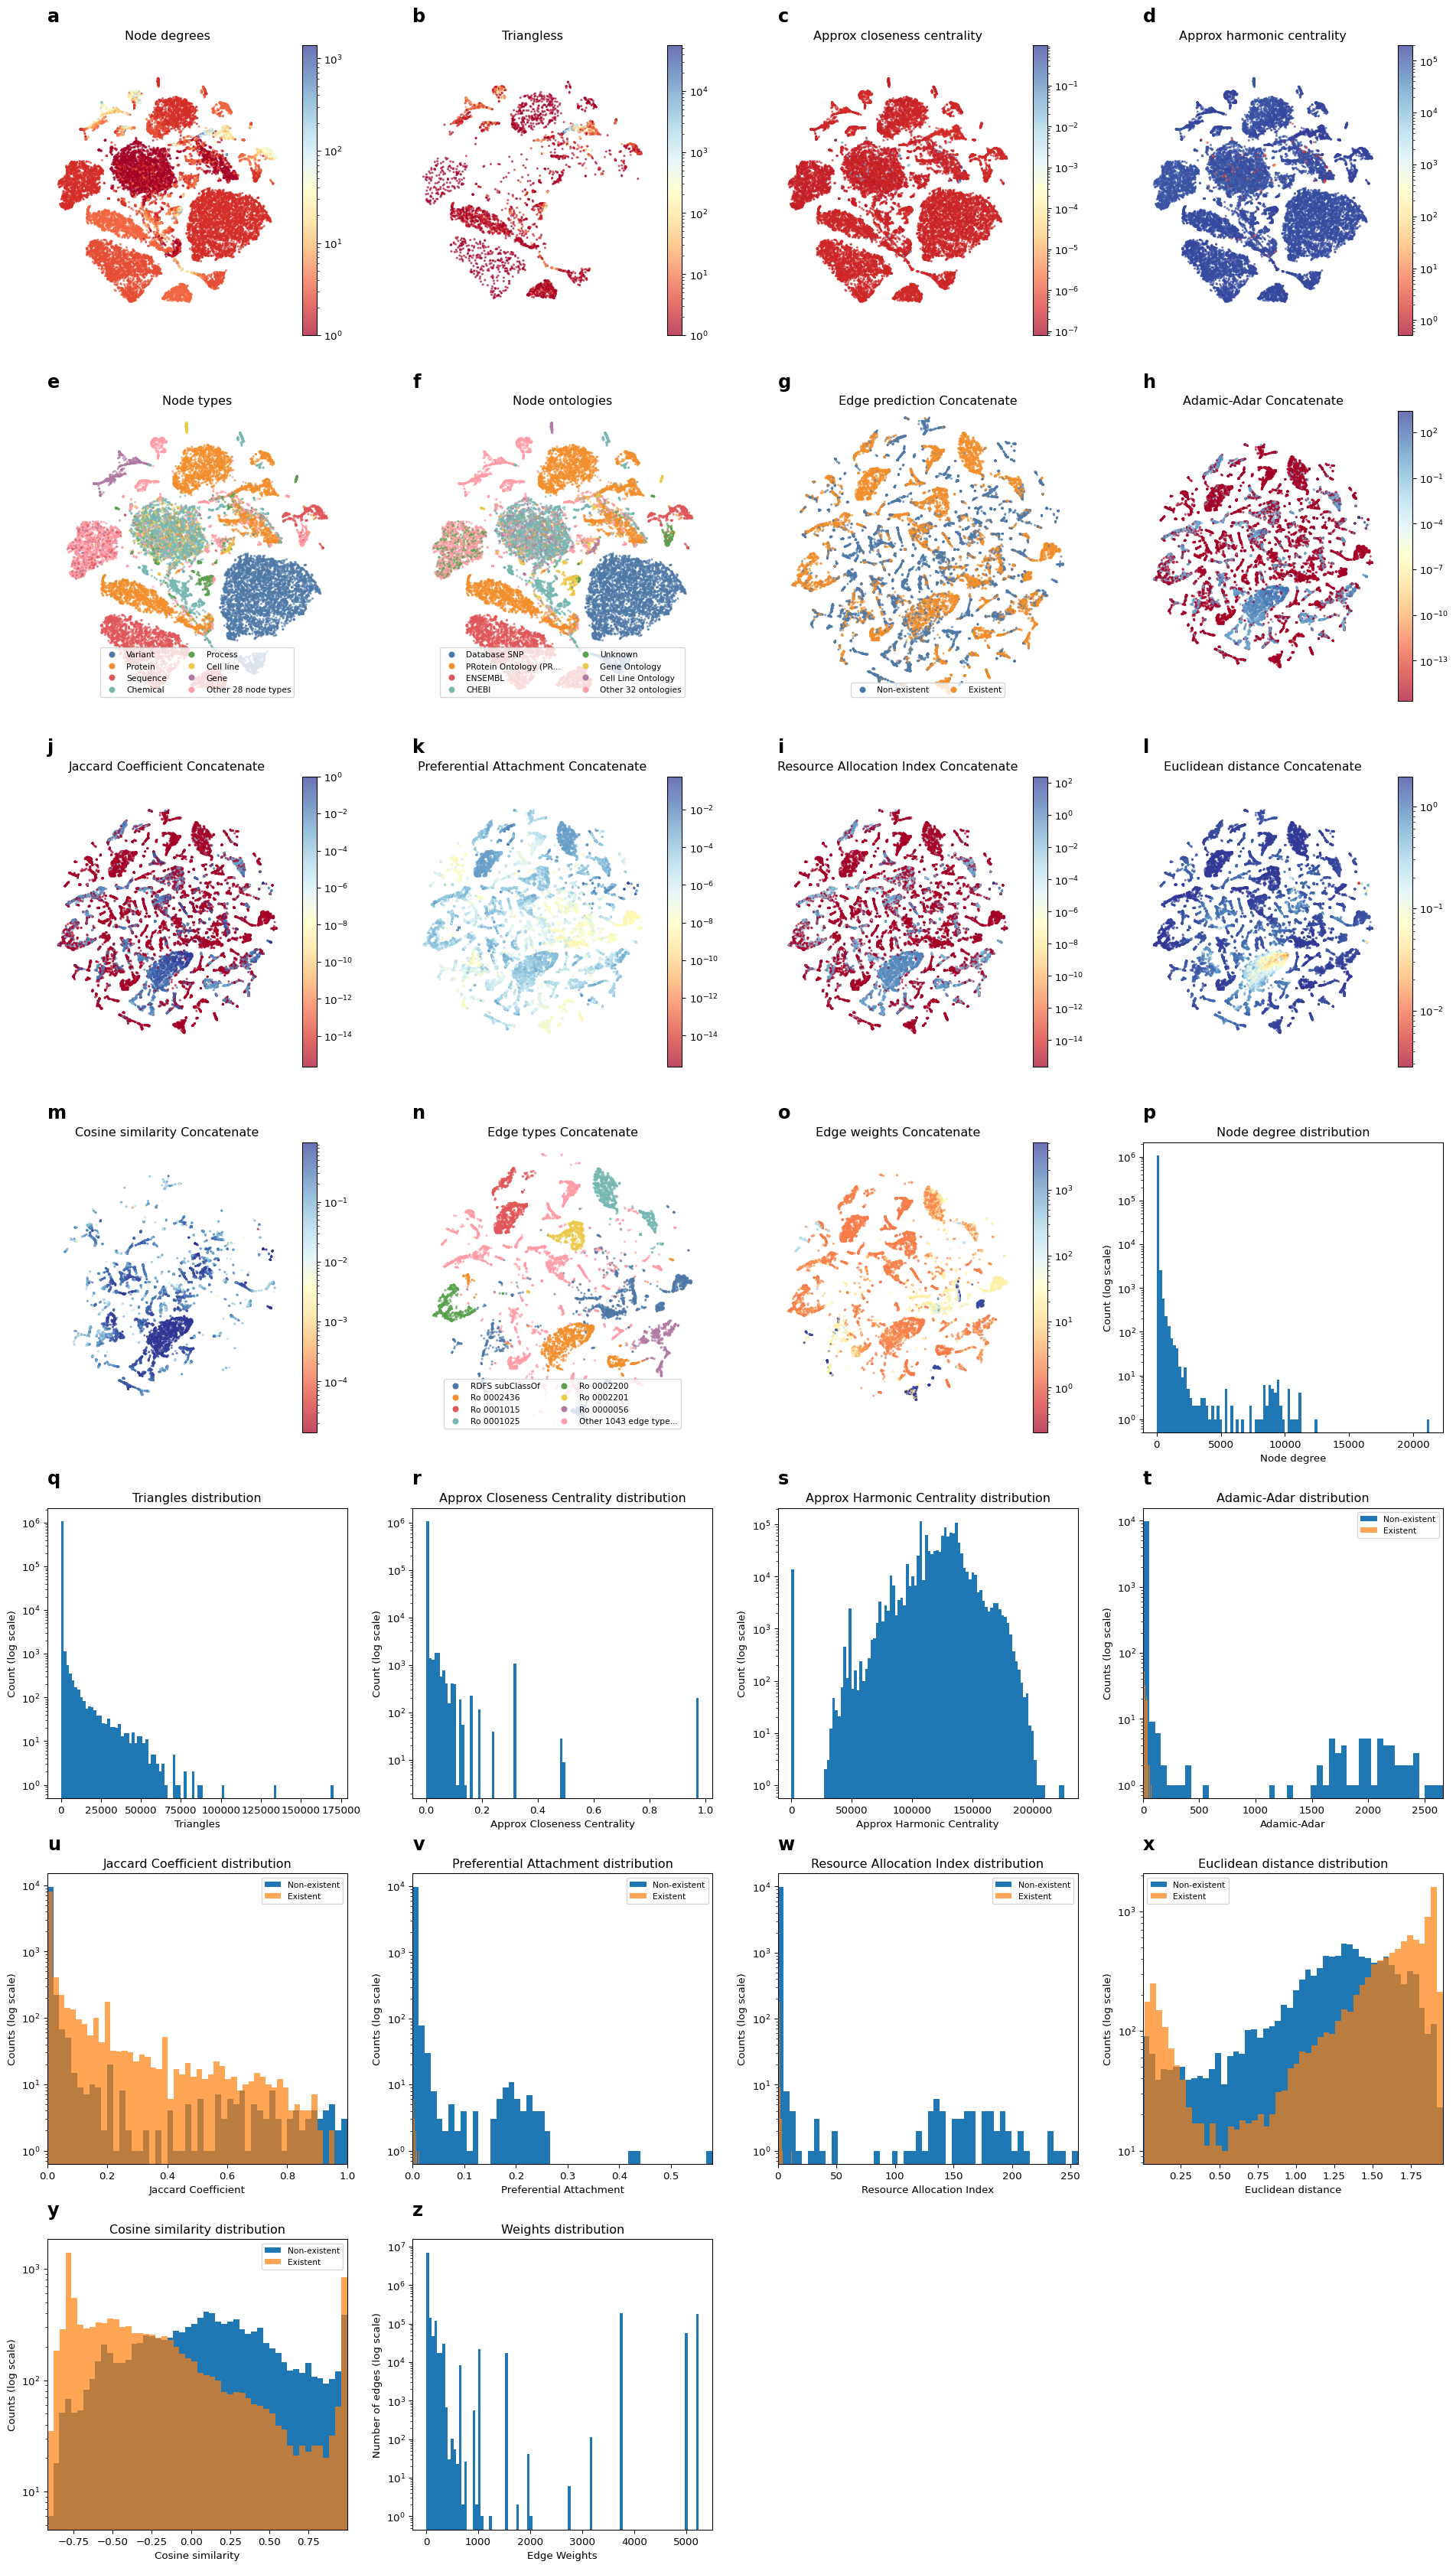

CPU times: user 8min 34s, sys: 12.6 s, total: 8min 47s
Wall time: 1min 14s


In [26]:
%%time
vis_conc = GraphVisualizer(npkg, verbose=True, edge_embedding_methods="Concatenate", rotate=False)
vis_conc.fit_and_plot_all(transe_embedding)